# Лабораторная №7 (облегчённая). RAG: как нарезка документов влияет на поиск

**Курс:** AI Agents for Enterprise Processes Automation · Неделя 7

**Что вы делаете:** запускаете ячейки по порядку сверху вниз (кнопка ▶ слева от ячейки или **Shift+Enter**). Весь код уже написан. Ваша задача — менять параметры там, где написано **✏️ ИЗМЕНИТЕ**, и записывать результаты в отчёт.

**Время:** ~45 минут. GPU не нужен.

## Шаг 1. Установка библиотек (~1 мин)

In [1]:
!pip -q install chromadb sentence-transformers langchain-text-splitters groq
print("Готово")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2 which is incompatible.
tweepy 4.17.0 requires oauthlib<4,>=3.2.0, but you have oauthlib 4.0.1 which is incompatible.
google-cloud-bigquery 3.47.0 requires python-dateutil<3.0.0,>=2.8.2, but you have python-dateutil 4.0.0 which is incompatible.
betterproto 2.0.0b7 requires python-dateutil<3.0,>=2.8, but you have python-dateutil 4.0.0 which is incompatible.
ibis-framework 9.5.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 4.0.0 which is incompatible.
bigframes 2.51.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 4.0.0 which is incompatible.
holidays 0.108 require

## Шаг 2. Создание базы знаний

База знаний вымышленной компании ОсОО «АлаТех Солюшнс»: **532 документа** (положения, тикеты HelpDesk, приказы, FAQ) и **10 тестовых вопросов** с эталонными ответами. Все имена, номера и суммы условны.

Просто запустите ячейку, код внутри можно не читать.

In [2]:
# @title Создать базу знаний (нажмите ▶)
import os
os.chdir('/content')
"""Генератор синтетической корпоративной базы знаний для Лабораторной №7.
Компания ОсОО «АлаТех Солюшнс» вымышленная; все имена, номера и суммы условны."""
import json, os, random, shutil, zipfile
random.seed(7)
OUT="kb_alatech"; shutil.rmtree(OUT, ignore_errors=True); os.makedirs(OUT+"/docs")

FILL=["Настоящий раздел применяется ко всем работникам Компании, включая работников филиалов.",
"Контроль за исполнением требований раздела возлагается на руководителей структурных подразделений.",
"Вопросы, не урегулированные настоящим разделом, решаются в соответствии с законодательством Кыргызской Республики.",
"Изменения в раздел вносятся приказом Генерального директора после согласования с юридическим отделом.",
"Работник знакомится с требованиями раздела под подпись при приёме на работу.",
"Документы, оформленные с нарушением установленного порядка, возвращаются инициатору на доработку.",
"Электронные копии документов хранятся в корпоративной системе документооборота не менее пяти лет.",
"Руководитель подразделения вправе запросить дополнительные пояснения у работника.",
"Отдел кадров ведёт учёт обращений и ежеквартально готовит сводный отчёт для руководства.",
"При возникновении спорных ситуаций работник может обратиться в комиссию по трудовым спорам.",
"Нарушение требований раздела может повлечь дисциплинарную ответственность.",
"Шаблоны заявлений и форм размещены на корпоративном портале в разделе «Документы».",
"Согласование осуществляется в электронном виде через систему документооборота.",
"Работник обязан своевременно информировать непосредственного руководителя об изменении обстоятельств.",
"Сроки, указанные в разделе, исчисляются со дня, следующего за днём наступления события."]
def pad(n): return " ".join(random.choice(FILL) for _ in range(n))

POL=[ # (id, title, dept, [(section, key_text)])
("POL-HR-001","Положение о ежегодных отпусках (редакция 2026 года)","HR",[
 ("1. Общие положения","Положение устанавливает порядок предоставления отпусков работникам ОсОО «АлаТех Солюшнс». Редакция 2026 года вступает в силу с 1 января 2026 года и заменяет редакцию 2023 года."),
 ("2. Продолжительность отпуска","Работникам предоставляется ежегодный основной оплачиваемый отпуск продолжительностью 24 календарных дня. Работникам со стажем работы в Компании свыше 3 лет дополнительно предоставляется 4 календарных дня."),
 ("3. Порядок оформления","Заявление на отпуск подаётся через корпоративный портал. Срок подачи заявления — не позднее чем за 14 календарных дней до начала отпуска. Отпуск может быть разделён на части, при этом одна из частей должна составлять не менее 14 календарных дней."),
 ("4. Перенос отпуска","Перенос отпуска допускается по согласованию с руководителем и отделом кадров. Неиспользованная часть отпуска может быть перенесена на следующий рабочий год, но не более 7 календарных дней."),
 ("5. Отзыв из отпуска","Отзыв работника из отпуска допускается только с его письменного согласия.")]),
("POL-HR-000","Положение о ежегодных отпусках (редакция 2023 года, утратило силу)","HR",[
 ("1. Общие положения","Редакция 2023 года утратила силу с 1 января 2026 года."),
 ("2. Продолжительность отпуска","Работникам предоставляется ежегодный оплачиваемый отпуск продолжительностью 20 календарных дней."),
 ("3. Порядок оформления","Заявление на отпуск подаётся в бумажном виде не позднее чем за 7 календарных дней до начала отпуска.")]),
("POL-HR-002","Положение об удалённой работе","HR",[
 ("1. Область применения","Положение регулирует гибридный и удалённый формат работы."),
 ("2. Право на удалённую работу","Право на удалённую работу возникает после успешного прохождения испытательного срока. Такой работник вправе выбрать дни удалённой работы по согласованию с руководителем. Их количество составляет не более 2 рабочих дней в неделю."),
 ("3. Рабочее время","В дни удалённой работы работник обязан быть на связи с 10:00 до 17:00 по времени Бишкека."),
 ("4. Оборудование","Компания предоставляет ноутбук; компенсация расходов на интернет составляет 1 000 сом в месяц.")]),
("POL-FIN-001","Положение о служебных командировках","FIN",[
 ("1. Общие положения","Командировка оформляется приказом на основании служебной записки руководителя."),
 ("2. Суточные","Суточные в командировках внутри Кыргызской Республики составляют 1 500 сом в сутки. При командировках в Казахстан и Узбекистан суточные составляют 45 долларов США в сутки. При командировках в другие страны суточные составляют 70 долларов США в сутки."),
 ("3. Проживание","Расходы на проживание возмещаются по фактическим затратам, но не более 120 долларов США в сутки за рубежом."),
 ("4. Авансовый отчёт","По возвращении работник составляет авансовый отчёт с приложением подтверждающих документов. Указанный отчёт представляется в бухгалтерию в течение 5 рабочих дней после возвращения. При непредставлении отчёта сумма аванса удерживается из заработной платы.")]),
("POL-FIN-002","Положение о закупках","FIN",[
 ("1. Общие положения","Закупки товаров и услуг осуществляются через отдел закупок."),
 ("2. Пороги согласования","Закупки до 50 000 сом согласует руководитель подразделения, свыше 50 000 сом — финансовый директор."),
 ("3. Сроки","Заявка на закупку рассматривается в течение 10 рабочих дней. Счёт поставщика оплачивается в течение 15 рабочих дней после подписания акта.")]),
("POL-IT-001","Политика информационной безопасности","IT",[
 ("1. Цели","Политика определяет требования к защите информационных активов Компании."),
 ("2. Пароли","Пароль учётной записи должен содержать не менее 12 символов, включая буквы разного регистра и цифры. Пароль меняется не реже одного раза в 90 дней. Повторное использование последних 5 паролей запрещено."),
 ("3. Инциденты","О любом инциденте информационной безопасности работник обязан сообщить в течение 1 часа с момента обнаружения по адресу security@alatech.kg или по внутреннему номеру 777."),
 ("4. Съёмные носители","Использование личных USB-накопителей на рабочих компьютерах запрещено."),
 ("5. VPN","Доступ к внутренним системам извне офиса осуществляется только через корпоративный VPN с двухфакторной аутентификацией.")]),
("POL-HR-003","Положение об обучении и развитии персонала","HR",[
 ("1. Общие положения","Компания поддерживает профессиональное развитие работников."),
 ("2. Бюджет","На каждого работника ежегодно планируется бюджет на обучение. Размер этого бюджета составляет до 60 000 сом в год. Неиспользованный бюджет на следующий год не переносится."),
 ("3. Обязательства работника","Если стоимость обучения превышает 30 000 сом, работник обязуется проработать в Компании не менее 12 месяцев после окончания обучения.")]),
("POL-HR-004","Положение о больничных и временной нетрудоспособности","HR",[
 ("1. Уведомление","О болезни работник уведомляет руководителя в первый день нетрудоспособности до 10:00."),
 ("2. Документы","Листок нетрудоспособности передаётся в отдел кадров в течение 3 рабочих дней после выхода на работу."),
 ("3. Дни без больничного","Работник может воспользоваться не более чем 3 днями отсутствия по болезни в год без листка нетрудоспособности.")]),
("POL-HR-005","Программа адаптации новых сотрудников","HR",[
 ("1. Наставник","Каждому новому работнику назначается наставник на период испытательного срока."),
 ("2. Испытательный срок","Испытательный срок составляет 3 месяца. Для руководителей испытательный срок составляет 6 месяцев."),
 ("3. План адаптации","В течение первой недели работник проходит вводный инструктаж и обучение по информационной безопасности.")]),
("POL-ADM-001","Правила пропускного режима и работы офиса","ADM",[
 ("1. Пропуска","Пропуск в офис выдаёт служба охраны на первом этаже в день выхода на работу."),
 ("2. Время работы офиса","Офис открыт с 8:00 до 21:00 в рабочие дни."),
 ("3. Гости","Гостевой пропуск заказывается через ресепшн не позднее чем за 1 рабочий день.")]),
("POL-LEG-001","Положение о защите персональных данных","LEG",[
 ("1. Общие положения","Обработка персональных данных осуществляется в соответствии с законодательством Кыргызской Республики."),
 ("2. Доступ","Доступ к персональным данным работников имеют только сотрудники отдела кадров и бухгалтерии."),
 ("3. Срок хранения","Персональные данные кандидатов, не принятых на работу, удаляются через 6 месяцев.")]),
("POL-ADM-002","Положение о корпоративном оборудовании","ADM",[
 ("1. Выдача","Ноутбук выдаётся работнику в первый рабочий день под подпись."),
 ("2. Утрата и повреждение","Об утрате или повреждении оборудования работник сообщает в ИТ-отдел в течение 24 часов."),
 ("3. Замена","Плановая замена ноутбука производится раз в 4 года.")]),
]
docs=[]
for pid,title,dept,secs in POL:
    body=[f"# {title}\n\nОсОО «АлаТех Солюшнс». Документ {pid}.\n"]
    for h,key in secs:
        a,b=random.randint(4,9),random.randint(4,9)
        body.append(f"## {h}\n\n{pad(a)} {key} {pad(b)}\n")
    docs.append((pid,"policy",dept,title,"\n".join(body)))

# Тикеты HelpDesk — дистракторы
topics=[("Не подключается VPN","Пользователь не может подключиться к VPN из дома.","Переустановлен клиент VPN, повторно привязан второй фактор."),
("Сброс пароля","Учётная запись заблокирована после нескольких неудачных попыток входа.","Пароль сброшен, пользователь задал новый пароль."),
("Вопрос по отпуску","Сотрудник уточняет, как подать заявление на отпуск через портал.","Направлена ссылка на раздел портала «Заявления»."),
("Командировка: билеты","Нужна помощь с бронированием билетов для командировки.","Заявка передана в административный отдел."),
("Не работает принтер","Принтер на 3 этаже не печатает.","Заменён картридж."),
("Доступ к папке","Нужен доступ к сетевой папке отдела продаж.","Доступ предоставлен после согласования руководителя."),
("Медленный ноутбук","Ноутбук работает медленно после обновления.","Очищен диск, обновлены драйверы."),
("Почта не синхронизируется","Почта на телефоне не синхронизируется.","Перенастроен профиль почты."),
("Подозрительное письмо","Получено письмо с просьбой ввести пароль на стороннем сайте.","Письмо заблокировано, проведена проверка почтового ящика."),
("Ошибка в 1С","При проведении документа в 1С появляется ошибка.","Исправлены права пользователя в 1С.")]
codes=["E-1042","E-2210","E-3007","E-0415","E-5120"]
for i in range(320):
    t=topics[i%len(topics)]; n=10000+i*7
    extra=f" Код ошибки {random.choice(codes)}." if "1С" in t[0] else ""
    txt=(f"# Тикет HD-{n}: {t[0]}\n\nСтатус: закрыт. Приоритет: {random.choice(['низкий','средний','высокий'])}. "
         f"Отдел заявителя: {random.choice(['Продажи','Бухгалтерия','Разработка','HR','Маркетинг'])}.\n\n"
         f"Описание: {t[1]}{extra}\n\nРешение: {t[2]} Время решения: {random.randint(1,48)} ч.\n")
    docs.append((f"HD-{n}","ticket","IT",t[0],txt))

# Приказы
subj=["О проведении инвентаризации","О назначении ответственного за пожарную безопасность","О поощрении работников","О командировании","О проведении обучения",
      "О назначении ответственного за охрану труда","О графике отпусков","О внесении изменений в штатное расписание"]
surn=["Абдыкадырова А. Т.","Садыков Б. А.","Иманалиев Н. К.","Токтогулова Д. М.","Осмонов Э. Р.","Мамбетова Ж. С.","Касымов Т. У."]
for i in range(140):
    num=i+1; s=subj[i%len(subj)]
    who=random.choice(surn)
    if num==87: s="О назначении ответственного за охрану труда"; who="Садыков Б. А."
    if num==78: s="О назначении ответственного за охрану труда"; who="Иманалиев Н. К."
    d=f"{random.randint(1,28):02d}.{random.randint(1,9):02d}.2026"
    txt=(f"# Приказ №{num}-к от {d} «{s}»\n\nВ целях обеспечения деятельности ОсОО «АлаТех Солюшнс» ПРИКАЗЫВАЮ:\n\n"
         f"1. {s.replace('О ','').capitalize()}: назначить исполнителем {who}.\n2. Контроль за исполнением приказа оставляю за собой.\n\nГенеральный директор К. Жээнбеков\n")
    docs.append((f"ORD-{num:03d}","order","ADM",f"Приказ №{num}-к","" + txt))

# FAQ по продукту AlaPay
faq=[("Как вернуть платёж?","Оператор поддержки может оформить возврат средств клиенту до 5 000 сом без подтверждения менеджера. Возврат свыше 5 000 сом требует подтверждения менеджера смены."),
("Какой лимит перевода?","Лимит одного перевода в AlaPay составляет 100 000 сом для верифицированных клиентов."),
("Как заблокировать карту?","Клиент может заблокировать карту в приложении в разделе «Карты».")]
gen_q=["Как изменить номер телефона","Почему не приходит SMS","Как подключить автоплатёж","Как оплатить коммунальные услуги","Как пополнить кошелёк","Как посмотреть историю","Как закрыть счёт","Как сменить PIN-код"]
for i in range(60):
    if i<len(faq): q,a=faq[i]
    else:
        q=gen_q[i%len(gen_q)]+"?"; a=f"Откройте приложение AlaPay, перейдите в раздел «Профиль» и следуйте инструкциям. Срок обработки — до {random.randint(1,3)} рабочих дней."
    docs.append((f"FAQ-{i+1:03d}","faq","SUPPORT",q,f"# AlaPay FAQ: {q}\n\n{a}\n"))

meta=[]
for did,typ,dept,title,txt in docs:
    fn=f"{did}.md"; open(f"{OUT}/docs/{fn}","w",encoding="utf-8").write(txt)
    meta.append({"doc_id":did,"file":fn,"type":typ,"dept":dept,"title":title})
json.dump(meta,open(f"{OUT}/metadata.json","w",encoding="utf-8"),ensure_ascii=False,indent=1)

Q=[
 ("q01","Сколько дней ежегодного оплачиваемого отпуска положено сотруднику АлаТех?","24 календарных дня основного отпуска; при стаже в Компании свыше 3 лет — ещё 4 календарных дня.",["24 календарных дня"],"POL-HR-001"),
 ("q02","За сколько дней нужно подать заявление на отпуск и можно ли делить отпуск на части?","Не позднее чем за 14 календарных дней; делить можно, но одна часть должна быть не менее 14 календарных дней.",["за 14 календарных дней"],"POL-HR-001"),
 ("q03","Какие суточные положены при командировке в Алматы?","45 долларов США в сутки (командировки в Казахстан).",["45 долларов США"],"POL-FIN-001"),
 ("q04","Сколько дней в неделю можно работать из дома и с какого момента?","Не более 2 рабочих дней в неделю, после успешного прохождения испытательного срока.",["не более 2 рабочих дней"],"POL-HR-002"),
 ("q05","Какие требования к паролю учётной записи?","Не менее 12 символов (буквы разного регистра и цифры), смена не реже раза в 90 дней, нельзя повторять последние 5 паролей.",["не менее 12 символов"],"POL-IT-001"),
 ("q06","Куда и в какой срок сообщать об инциденте информационной безопасности?","В течение 1 часа на security@alatech.kg или по внутреннему номеру 777.",["security@alatech.kg"],"POL-IT-001"),
 ("q07","В какой срок нужно сдать авансовый отчёт после командировки?","В течение 5 рабочих дней после возвращения из командировки.",["в течение 5 рабочих дней"],"POL-FIN-001"),
 ("q08","Какой годовой бюджет на обучение у одного сотрудника?","До 60 000 сом в год; неиспользованный остаток не переносится.",["60 000 сом"],"POL-HR-003"),
 ("q09","Кто назначен ответственным по приказу №87-к?","Садыков Б. А. — ответственный за охрану труда.",["Приказ №87-к"],"ORD-087"),
 ("q10","До какой суммы оператор может вернуть клиенту деньги в AlaPay без подтверждения менеджера?","До 5 000 сом; свыше — нужно подтверждение менеджера смены.",["до 5 000 сом без подтверждения"],"FAQ-001")]
json.dump([{"id":a,"question":b,"reference":c,"gold_snippets":d,"gold_doc_id":e} for a,b,c,d,e in Q],
          open(f"{OUT}/questions.json","w",encoding="utf-8"),ensure_ascii=False,indent=1)
open(f"{OUT}/README.md","w",encoding="utf-8").write(
"# База знаний ОсОО «АлаТех Солюшнс» (синтетическая)\n\nДатасет для Лабораторной №7 курса AI Agents for Enterprise Processes Automation.\n"
"Компания, люди, номера и суммы вымышлены.\n\n- docs/ — документы в Markdown\n- metadata.json — doc_id, тип, отдел, заголовок\n"
"- questions.json — 10 тестовых вопросов: эталонный ответ (reference), gold_snippets (фрагмент, который должен попасть в найденный контекст), gold_doc_id\n")
print(f"База знаний создана: {len(docs)} документов, 10 вопросов")

База знаний создана: 532 документов, 10 вопросов


## Шаг 3. Смотрим на данные

In [3]:
import json, glob
from collections import Counter

docs = []
meta = {m["doc_id"]: m for m in json.load(open("kb_alatech/metadata.json", encoding="utf-8"))}
for path in sorted(glob.glob("kb_alatech/docs/*.md")):
    doc_id = os.path.basename(path)[:-3]
    docs.append({"doc_id": doc_id, "text": open(path, encoding="utf-8").read(), **meta[doc_id]})
questions = json.load(open("kb_alatech/questions.json", encoding="utf-8"))

print("Документов:", len(docs), "| вопросов:", len(questions))
print("По типам:", dict(Counter(d["type"] for d in docs)))
for t in ["policy", "ticket", "order", "faq"]:
    lens = [len(d["text"]) for d in docs if d["type"] == t]
    print(f"  {t:7s} средняя длина: {sum(lens)//len(lens)} символов")

print("\nТестовые вопросы:")
for q in questions:
    print(f"  {q['id']}: {q['question']}")

Документов: 532 | вопросов: 10
По типам: {'faq': 60, 'ticket': 320, 'order': 140, 'policy': 12}
  policy  средняя длина: 4608 символов
  ticket  средняя длина: 236 символов
  order   средняя длина: 293 символов
  faq     средняя длина: 156 символов

Тестовые вопросы:
  q01: Сколько дней ежегодного оплачиваемого отпуска положено сотруднику АлаТех?
  q02: За сколько дней нужно подать заявление на отпуск и можно ли делить отпуск на части?
  q03: Какие суточные положены при командировке в Алматы?
  q04: Сколько дней в неделю можно работать из дома и с какого момента?
  q05: Какие требования к паролю учётной записи?
  q06: Куда и в какой срок сообщать об инциденте информационной безопасности?
  q07: В какой срок нужно сдать авансовый отчёт после командировки?
  q08: Какой годовой бюджет на обучение у одного сотрудника?
  q09: Кто назначен ответственным по приказу №87-к?
  q10: До какой суммы оператор может вернуть клиенту деньги в AlaPay без подтверждения менеджера?


## Шаг 4. RAG-конвейер (готовый код)

Здесь три функции из лекции:
- `make_chunks` — режет документы на чанки размером `chunk_size` с перекрытием `overlap`;
- `build_index` — превращает чанки в векторы и кладёт в ChromaDB;
- `retrieve` — находит 5 чанков, ближайших к вопросу.

Метрики поиска: **Hit@1** — доля вопросов, где правильный чанк на 1-м месте; **Hit@5** — в первой пятёрке; **MRR** — среднее 1/позиция правильного чанка.

Первый запуск скачает модель эмбеддингов (~0,5 ГБ, около минуты).

In [4]:
import chromadb
from chromadb.utils import embedding_functions
from langchain_text_splitters import RecursiveCharacterTextSplitter

EMB_MODEL = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
ef = embedding_functions.SentenceTransformerEmbeddingFunction(model_name=EMB_MODEL)
client = chromadb.EphemeralClient()

def make_chunks(chunk_size, overlap):
    splitter = RecursiveCharacterTextSplitter(chunk_size=chunk_size, chunk_overlap=overlap,
                                              separators=["\n\n", "\n", ". ", " ", ""])
    chunks = []
    for d in docs:
        for i, piece in enumerate(splitter.split_text(d["text"])):
            chunks.append({"id": f"{d['doc_id']}#{i}", "text": piece, "doc_id": d["doc_id"]})
    return chunks

def build_index(chunks, name):
    try:
        client.delete_collection(name)
    except Exception:
        pass
    col = client.create_collection(name, embedding_function=ef, metadata={"hnsw:space": "cosine"})
    for i in range(0, len(chunks), 256):
        b = chunks[i:i + 256]
        col.add(ids=[c["id"] for c in b], documents=[c["text"] for c in b],
                metadatas=[{"doc_id": c["doc_id"]} for c in b])
    return col

def retrieve(col, question, k=5):
    r = col.query(query_texts=[question], n_results=k, include=["documents", "metadatas", "distances"])
    return [{"text": t, "doc_id": m["doc_id"], "distance": d}
            for t, m, d in zip(r["documents"][0], r["metadatas"][0], r["distances"][0])]

def is_relevant(text, q):
    return any(s in text for s in q["gold_snippets"])

def evaluate(col):
    hit1 = hit5 = mrr = 0
    for q in questions:
        ranks = [i for i, c in enumerate(retrieve(col, q["question"])) if is_relevant(c["text"], q)]
        if ranks:
            hit5 += 1; hit1 += ranks[0] == 0; mrr += 1 / (ranks[0] + 1)
    n = len(questions)
    return {"hit@1": hit1 / n, "hit@5": hit5 / n, "MRR": round(mrr / n, 3)}

print("Конвейер готов")

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

... (4 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Конвейер готов


## Шаг 5. Эксперимент: 3 конфигурации чанкинга

Сравниваем мелкие, средние и крупные чанки с перекрытием 15%. Займёт 2–3 минуты.

✏️ **ИЗМЕНИТЕ** (по желанию): можно добавить свои конфигурации в список `CONFIGS`, например `(500, 0)` или `(500, 150)`, чтобы проверить влияние overlap.

In [21]:
import pandas as pd

CONFIGS = [(200, 30), (500, 75), (1000, 150), (500,50)]   # (chunk_size, overlap)

collections, rows = {}, []
for size, ov in CONFIGS:
    chunks = make_chunks(size, ov)
    col = build_index(chunks, f"kb_{size}_{ov}")
    collections[(size, ov)] = col
    rows.append({"chunk_size": size, "overlap": ov, "чанков": len(chunks), **evaluate(col)})
    print(f"готово: chunk_size={size}, overlap={ov}")

results = pd.DataFrame(rows)
results

готово: chunk_size=200, overlap=30
готово: chunk_size=500, overlap=75
готово: chunk_size=1000, overlap=150
готово: chunk_size=500, overlap=50


,chunk_size,overlap,чанков,hit@1,hit@5,MRR
0,200,30,1320,0.5,0.6,0.533
1,500,75,697,0.5,0.8,0.592
2,1000,150,629,0.3,0.5,0.353
3,500,50,696,0.4,0.8,0.525


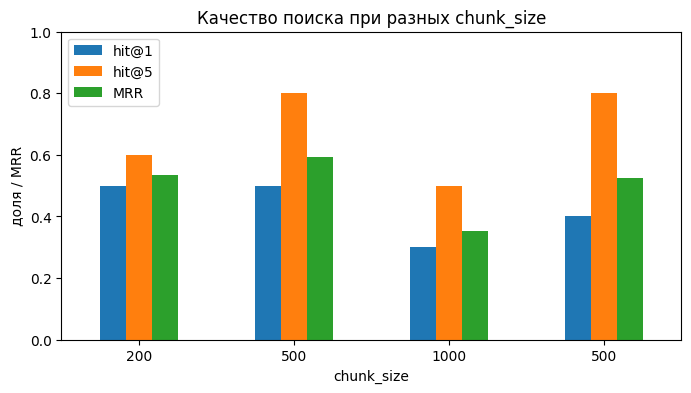

In [22]:
ax = results.plot.bar(x="chunk_size", y=["hit@1", "hit@5", "MRR"], rot=0, figsize=(8, 4),
                      title="Качество поиска при разных chunk_size")
ax.set_ylim(0, 1); ax.set_ylabel("доля / MRR");

## Шаг 6. Что именно нашёл поиск

Посмотрите на top-5 найденных чанков для одного вопроса. ✔ — в чанке есть правильный ответ.

✏️ **ИЗМЕНИТЕ** `QID` и `CONFIG` и запустите ячейку несколько раз. Обязательно посмотрите **q03** (суточные в Алматы) и **q09** (приказ №87-к).

In [25]:
QID = "q09"           # ✏️ номер вопроса: q01 ... q10
CONFIG = (500, 75)    # ✏️ одна из конфигураций шага 5

q = next(x for x in questions if x["id"] == QID)
print(f"{q['id']}: {q['question']}\nНужный документ: {q['gold_doc_id']}\n")
for i, c in enumerate(retrieve(collections[CONFIG], q["question"]), 1):
    mark = "✔" if is_relevant(c["text"], q) else " "
    print(f"{mark} {i}. {c['doc_id']:12s} dist={c['distance']:.3f}  {c['text'][:90]!r}")

q09: Кто назначен ответственным по приказу №87-к?
Нужный документ: ORD-087

  1. ORD-068      dist=0.285  '# Приказ №68-к от 01.02.2026 «О командировании»\n\nВ целях обеспечения деятельности ОсОО «Ал'
  2. ORD-108      dist=0.322  '# Приказ №108-к от 04.06.2026 «О командировании»\n\nВ целях обеспечения деятельности ОсОО «А'
✔ 3. ORD-087      dist=0.324  '# Приказ №87-к от 25.09.2026 «О назначении ответственного за охрану труда»\n\nВ целях обеспе'
  4. ORD-116      dist=0.325  '# Приказ №116-к от 18.01.2026 «О командировании»\n\nВ целях обеспечения деятельности ОсОО «А'
  5. ORD-092      dist=0.326  '# Приказ №92-к от 16.01.2026 «О командировании»\n\nВ целях обеспечения деятельности ОсОО «Ал'


## Шаг 7. Генерация ответов через LLM

Берём лучшую конфигурацию и просим модель ответить на 10 вопросов **только по найденному контексту**.

Нужен ключ Groq: [console.groq.com](https://console.groq.com) → API Keys. Ячейка попросит его ввести (ключ не сохраняется в ноутбуке).

✏️ **ИЗМЕНИТЕ** `BEST` на лучшую конфигурацию из шага 5. Если Groq сообщит, что модель недоступна, возьмите актуальное название на console.groq.com/docs/models.

In [27]:
import os, time
from getpass import getpass
from groq import Groq

if "GROQ_API_KEY" not in os.environ:
    os.environ["GROQ_API_KEY"] = getpass("Groq API key: ")
llm = Groq()
LLM_MODEL = "openai/gpt-oss-120b"      # обновлено на поддерживаемую модель Groq
BEST = (500, 75)                      # ✏️ лучшая конфигурация из шага 5

SYSTEM = ("Ты ассистент сотрудников компании АлаТех. Отвечай ТОЛЬКО на основе контекста. "
          "Если ответа в контексте нет, напиши: «В документах нет информации». "
          "После ответа укажи doc_id источника в квадратных скобках. Отвечай кратко.")

def generate_answer(question, contexts):
    ctx = "\n\n".join(f"[{c['doc_id']}] {c['text']}" for c in contexts)
    r = llm.chat.completions.create(model=LLM_MODEL, temperature=0, messages=[
        {"role": "system", "content": SYSTEM},
        {"role": "user", "content": f"Контекст:\n{ctx}\n\nВопрос: {question}"}])
    return r.choices[0].message.content

answers = []
for q in questions:
    ctx = retrieve(collections[BEST], q["question"])
    answers.append({"id": q["id"], "вопрос": q["question"],
                    "найден ли нужный чанк": "да" if any(is_relevant(c["text"], q) for c in ctx) else "нет",
                    "эталон": q["reference"], "ответ модели": generate_answer(q["question"], ctx)})
    time.sleep(1)   # чтобы не упереться в лимит бесплатного тарифа

pd.set_option("display.max_colwidth", None)
pd.DataFrame(answers)

,id,вопрос,найден ли нужный чанк,эталон,ответ модели
0,q01,Сколько дней ежегодного оплачиваемого отпуска положено сотруднику АлаТех?,да,24 календарных дня основного отпуска; при стаже в Компании свыше 3 лет — ещё 4 календарных дня.,24 календарных дня [POL-HR-001]
1,q02,За сколько дней нужно подать заявление на отпуск и можно ли делить отпуск на части?,да,"Не позднее чем за 14 календарных дней; делить можно, но одна часть должна быть не менее 14 календарных дней.","Заявление нужно подать не позднее чем за 14 календарных дней до начала отпуска. Отпуск можно разделять на части, при этом одна из частей должна быть не короче 14 календарных дней. 【POL-HR-001】"
2,q03,Какие суточные положены при командировке в Алматы?,нет,45 долларов США в сутки (командировки в Казахстан).,В документах нет информации. [HD-11624]
3,q04,Сколько дней в неделю можно работать из дома и с какого момента?,да,"Не более 2 рабочих дней в неделю, после успешного прохождения испытательного срока.","Не более 2 рабочих дней в неделю, выбранных сотрудником после согласования с руководителем. [POL-HR-002]"
4,q05,Какие требования к паролю учётной записи?,нет,"Не менее 12 символов (буквы разного регистра и цифры), смена не реже раза в 90 дней, нельзя повторять последние 5 паролей.",В документах нет информации. [HD-11827]
5,q06,Куда и в какой срок сообщать об инциденте информационной безопасности?,да,В течение 1 часа на security@alatech.kg или по внутреннему номеру 777.,Сообщать по адресу security@alatech.kg или по внутреннему номеру 777 в течение 1 часа с момента обнаружения инцидента. [POL-IT-001]
6,q07,В какой срок нужно сдать авансовый отчёт после командировки?,да,В течение 5 рабочих дней после возвращения из командировки.,Отчёт следует представить в бухгалтерию в течение 5 рабочих дней после возвращения. [POL-FIN-001]
7,q08,Какой годовой бюджет на обучение у одного сотрудника?,да,До 60 000 сом в год; неиспользованный остаток не переносится.,До 60 000 сом в год. [POL-HR-003]
8,q09,Кто назначен ответственным по приказу №87-к?,да,Садыков Б. А. — ответственный за охрану труда.,Садыков Б. А. [ORD-087]
9,q10,До какой суммы оператор может вернуть клиенту деньги в AlaPay без подтверждения менеджера?,да,До 5 000 сом; свыше — нужно подтверждение менеджера смены.,До 5 000 сом. [FAQ-001]


## Шаг 8. Отчёт

Сравните колонки **«эталон»** и **«ответ модели»** и оцените каждый ответ: **1** — верно, **0,5** — частично, **0** — неверно или «нет информации».

Ответьте в отчёте на три вопроса:
1. Какая конфигурация оказалась лучшей по MRR и почему? Объясните, чем плохи слишком мелкие и слишком крупные чанки.
2. Какую точность ответов (сумма баллов / 10) дала лучшая конфигурация? Совпадают ли ошибки в ответах с колонкой «найден ли нужный чанк»?
3. Выберите один вопрос, на котором система ошиблась, и объясните причину: **поиск** не нашёл чанк или **модель** ошиблась при правильном контексте? Что можно было бы улучшить?

*Подсказка к вопросу 3: посмотрите, сколько в базе положений об отпусках.*